# FST and frequency cross-check with scikit-allel

Goals:
1. Independently recompute allele frequencies from raw genotypes (validate the bcftools results)
2. Compute Hudson FST between YRI, CEU and CHB
3. Compare FST with the simple frequency-difference ranking used earlier

In [1]:
import numpy as np
import pandas as pd
import allel
import matplotlib.pyplot as plt

callset = allel.read_vcf(
    "../data/processed/chr22_YRI_CEU_CHB_snps.vcf.gz",
    fields=["samples", "variants/POS", "variants/REF", "variants/ALT", "calldata/GT"],
    alt_number=1,
)

samples = callset["samples"]
pos = callset["variants/POS"]
gt = allel.GenotypeArray(callset["calldata/GT"])

print("Variants x samples x ploidy:", gt.shape)

Variants x samples x ploidy: (416715, 310, 2)


In [2]:
panel = pd.read_csv(
    "../data/raw/1000_genomes/integrated_call_samples_v3.20130502.ALL.panel.txt",
    sep=r"\s+",
)
sample_pop = panel.set_index("sample").loc[samples, "pop"].values

subpops = {p: np.where(sample_pop == p)[0].tolist() for p in ["YRI", "CEU", "CHB"]}
print({p: len(idx) for p, idx in subpops.items()})

{'YRI': 108, 'CEU': 99, 'CHB': 103}


In [3]:
ac = gt.count_alleles_subpops(subpops, max_allele=1)

freqs = pd.DataFrame({
    "pos": pos,
    "af_YRI_allel": ac["YRI"].to_frequencies()[:, 1],
    "af_CEU_allel": ac["CEU"].to_frequencies()[:, 1],
    "af_CHB_allel": ac["CHB"].to_frequencies()[:, 1],
})
freqs.head()

,pos,af_YRI_allel,af_CEU_allel,af_CHB_allel
0,16050115,0.046296,0.000000,0.0
1,16050213,0.032407,0.000000,0.0
2,16050607,0.000000,0.005051,0.0
3,16050783,0.018519,0.000000,0.0
4,16050840,0.000000,0.030303,0.0


In [4]:
final = pd.read_csv("../results/final_variant_annotations.csv")
check = final.merge(freqs, on="pos", how="inner")

for p in ["YRI", "CEU", "CHB"]:
    diff = (check[f"af_{p}"] - check[f"af_{p}_allel"]).abs().max()
    print(f"{p}: max difference between bcftools and scikit-allel = {diff:.6f}")

print(f"{len(check)} of {len(final)} shortlisted variants checked (the rest are indels)")

YRI: max difference between bcftools and scikit-allel = 0.000000
CEU: max difference between bcftools and scikit-allel = 0.000000
CHB: max difference between bcftools and scikit-allel = 0.000000
13 of 15 shortlisted variants checked (the rest are indels)


In [5]:
pairs = [("YRI", "CEU"), ("YRI", "CHB"), ("CEU", "CHB")]
fst_df = pd.DataFrame({"pos": pos})

for a, b in pairs:
    seg = (ac[a] + ac[b]).is_segregating()
    num, den = allel.hudson_fst(ac[a], ac[b])
    per_variant = np.full(len(pos), np.nan)
    per_variant[seg] = num[seg] / den[seg]
    fst_df[f"fst_{a}_{b}"] = per_variant

    fst_mean, se, _, _ = allel.average_hudson_fst(ac[a][seg], ac[b][seg], blen=10000)
    print(f"{a} vs {b}: genome-wide (chr22) Hudson FST = {fst_mean:.3f} +/- {se:.3f}")

YRI vs CEU: genome-wide (chr22) Hudson FST = 0.140 +/- 0.005
YRI vs CHB: genome-wide (chr22) Hudson FST = 0.174 +/- 0.007
CEU vs CHB: genome-wide (chr22) Hudson FST = 0.108 +/- 0.006


In [6]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [7]:
df = freqs.merge(fst_df, on="pos")
df["max_diff"] = df[["af_YRI_allel", "af_CEU_allel", "af_CHB_allel"]].max(axis=1) - \
                 df[["af_YRI_allel", "af_CEU_allel", "af_CHB_allel"]].min(axis=1)
df["max_fst"] = df[[c for c in df.columns if c.startswith("fst_")]].max(axis=1)

# 1. Do the two measures agree overall?
print("Spearman correlation (max_diff vs max_fst):",
      round(df["max_diff"].corr(df["max_fst"], method="spearman"), 3))

# 2. Where do our 15 shortlisted variants rank by FST?
df["fst_percentile"] = df["max_fst"].rank(pct=True) * 100
ours = df[df["pos"].isin(final["pos"])][["pos", "max_diff", "max_fst", "fst_percentile"]]
ours = ours.merge(final[["pos", "SYMBOL"]], on="pos")
ours.sort_values("max_fst", ascending=False)

Spearman correlation (max_diff vs max_fst): 0.968


,pos,max_diff,max_fst,fst_percentile,SYMBOL
9,46500973,0.985886,0.985729,99.999760,FLJ27365
11,46762214,0.953479,0.952855,99.999040,CELSR1
0,21508002,0.951681,0.951040,99.998800,NaN
5,40540185,0.939365,0.938089,99.998560,TNRC6B
1,32908738,0.917476,0.917073,99.995681,SYN3
6,40597667,0.911588,0.909641,99.995441,TNRC6B
12,46828354,0.901205,0.896333,99.992321,CELSR1
10,46652959,0.900081,0.894752,99.991841,PKDREJ
8,46394928,0.893204,0.892683,99.991481,NaN
2,36556964,0.889024,0.885784,99.990881,APOL3


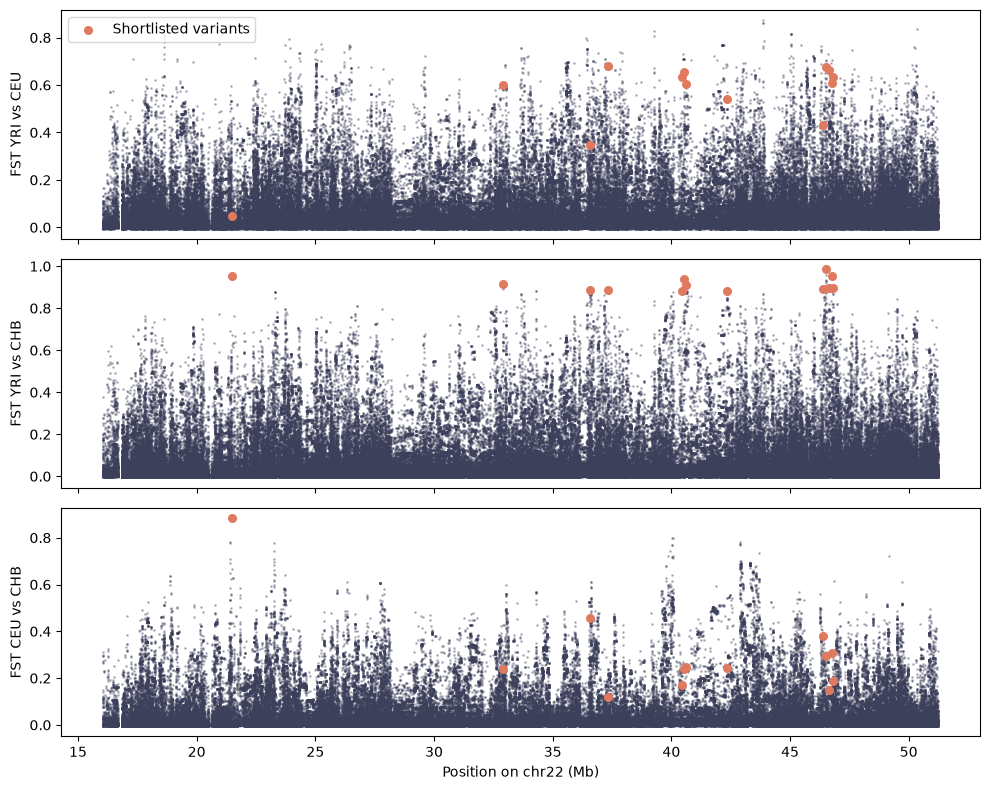

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
highlight = df["pos"].isin(final["pos"])

for ax, (a, b) in zip(axes, pairs):
    col = f"fst_{a}_{b}"
    ax.scatter(df["pos"] / 1e6, df[col], s=1, color="#3d405b", alpha=0.3, rasterized=True)
    ax.scatter(df.loc[highlight, "pos"] / 1e6, df.loc[highlight, col],
               s=30, color="#e07a5f", label="Shortlisted variants")
    ax.set_ylabel(f"FST {a} vs {b}")

axes[0].legend(loc="upper left")
axes[-1].set_xlabel("Position on chr22 (Mb)")
plt.tight_layout()
plt.savefig("../results/fst_chr22.png", dpi=150)
plt.show()

In [9]:
ours.to_csv("../results/shortlist_fst_check.csv", index=False)